Analytical Gradient: [ 7 10]
h: 0.1
Forward: [ 7.1 10.2] Error: 0.22360679774999487
Central: [ 7. 10.] Error: 1.3873790429220374e-14
h: 0.01
Forward: [ 7.01 10.02] Error: 0.022360679775006158
Central: [ 7. 10.] Error: 8.054559009987823e-14
h: 0.001
Forward: [ 7.001 10.002] Error: 0.002236067977078307
Central: [ 7. 10.] Error: 3.9021671846472775e-13
h: 0.0001
Forward: [ 7.0001 10.0002] Error: 0.00022360680399829592
Central: [ 7. 10.] Error: 1.999646527344254e-11
h: 1e-05
Forward: [ 7.00001 10.00002] Error: 2.23608600303635e-05
Central: [ 7. 10.] Error: 1.1153412658255166e-10
h: 1e-06
Forward: [ 7.000001 10.000002] Error: 2.236763691119425e-06
Central: [ 7. 10.] Error: 3.8919001487052306e-10
h: 1e-07
Forward: [ 7.00000008 10.00000021] Error: 2.213491680803739e-07
Central: [ 6.99999999 10.        ] Error: 7.153059341947846e-09
h: 1e-08
Forward: [6.99999987 9.99999994] Error: 1.4473787132946844e-07
Central: [ 6.99999987 10.00000003] Error: 1.343201523366536e-07


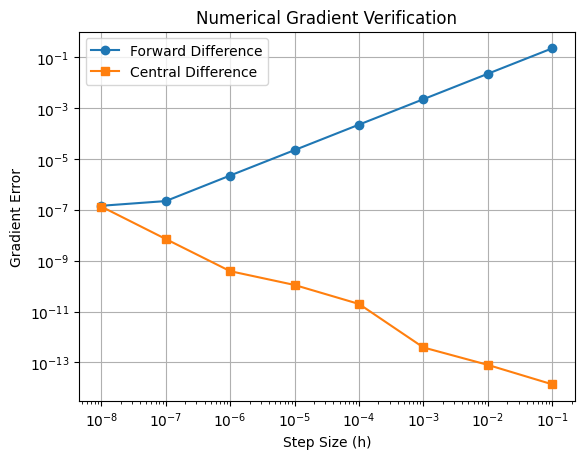

In [13]:

import numpy as np
import matplotlib.pyplot as plt

# Define loss function
def loss(x, y):
    return x**2 + 3*x*y + 2*y**2

# Analytical gradients
def analytical(x, y):
    return np.array([2*x + 3*y, 3*x + 4*y])

# Numerical gradients
def forward(x, y, h):
    return np.array([
        (loss(x+h, y)-loss(x, y))/h,
        (loss(x, y+h)-loss(x, y))/h
    ])

def central(x, y, h):
    return np.array([
        (loss(x+h, y)-loss(x-h, y))/(2*h),
        (loss(x, y+h)-loss(x, y-h))/(2*h)
    ])

x, y = 2, 1
true_grad = analytical(x, y)

steps = np.logspace(-1, -8, 8)
forward_errors = []
central_errors = []

print("Analytical Gradient:", true_grad)

for h in steps:
    fg = forward(x, y, h)
    cg = central(x, y, h)

    fe = np.linalg.norm(fg - true_grad)
    ce = np.linalg.norm(cg - true_grad)

    forward_errors.append(fe)
    central_errors.append(ce)

    print("h:", h)
    print("Forward:", fg, "Error:", fe)
    print("Central:", cg, "Error:", ce)

# Plot gradient errors
plt.loglog(steps, forward_errors, 'o-', label='Forward Difference')
plt.loglog(steps, central_errors, 's-', label='Central Difference')
plt.xlabel('Step Size (h)')
plt.ylabel('Gradient Error')
plt.title('Numerical Gradient Verification')
plt.legend()
plt.grid()
plt.show()
